# Các bước lặp của thuật toán K-means (mục 8.1.3)

Mỗi hình: tâm cụm hiện tại (dấu X), điểm tô màu theo cụm được gán, mũi tên chỉ vị trí tâm mới

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs

IMAGES = Path('.')   # thư mục images/ (notebook chạy trong images/)

X, y = make_blobs(n_samples=300, centers=3, cluster_std=0.9, random_state=7)
centers = X[np.flatnonzero(y == 0)[:3]]     # khởi tạo kém: cả ba tâm lấy từ cùng một cụm thật
colors = np.array(['#1F77B4', '#2CA02C', '#D62728'])

Vẽ hình và lưu ảnh.

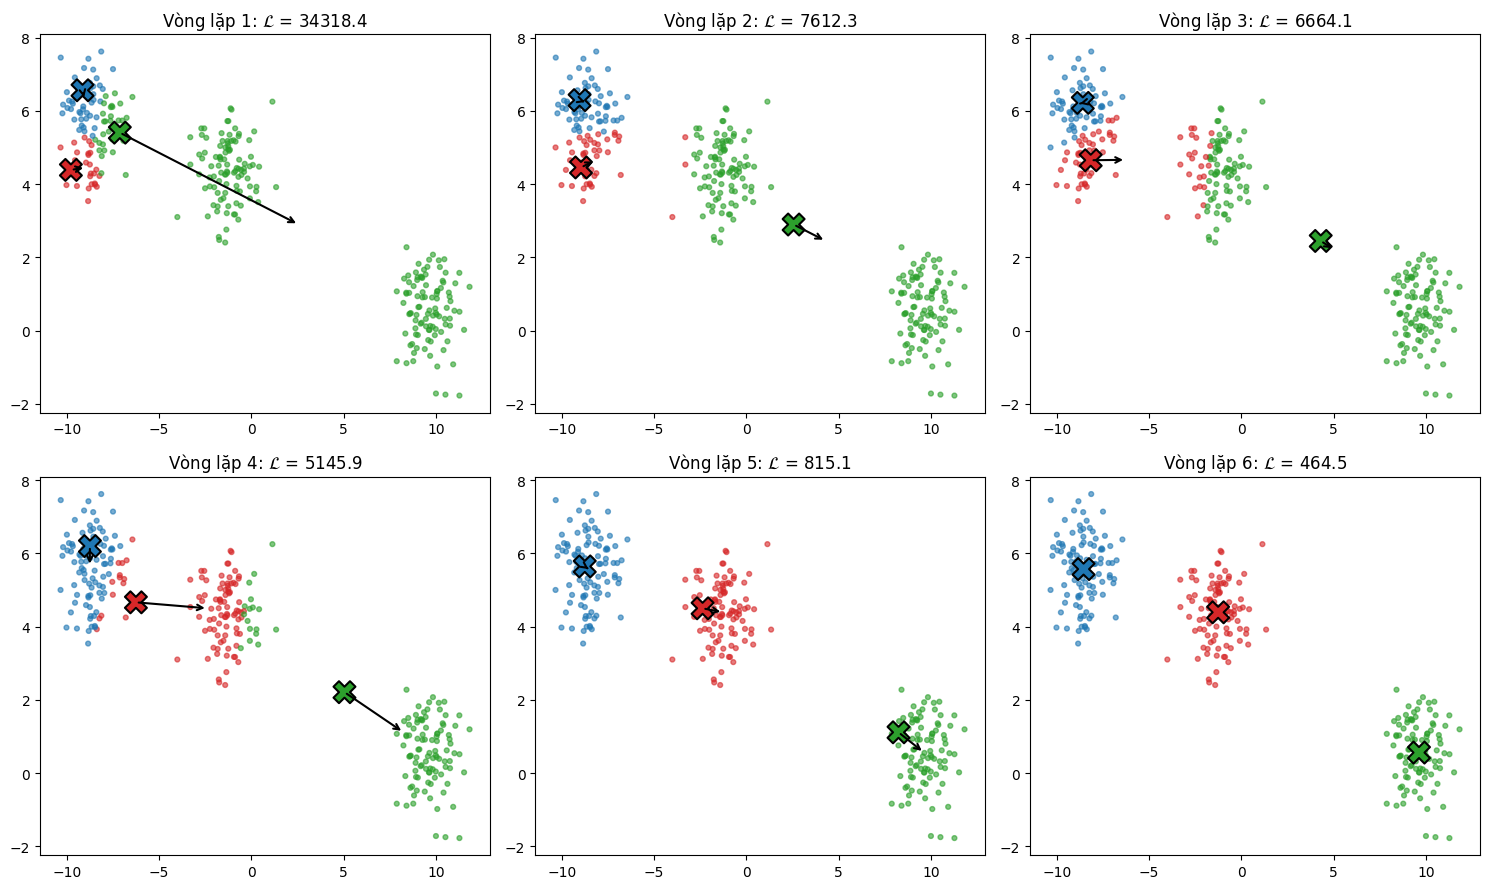

In [2]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for t, ax in enumerate(axes.ravel()):
    labels = np.linalg.norm(X[:, None] - centers[None], axis=2).argmin(axis=1)   # bước gán
    L = np.sum((X - centers[labels])**2)                                         # hàm mất mát
    new_centers = np.array([X[labels == k].mean(axis=0) for k in range(3)])     # bước cập nhật
    ax.scatter(X[:, 0], X[:, 1], c=colors[labels], s=12, alpha=0.6)
    ax.scatter(*centers.T, marker='X', s=250, c=colors, edgecolors='k', linewidths=1.5)
    for old, new in zip(centers, new_centers):
        if np.linalg.norm(new - old) > 0.05:
            ax.annotate('', xy=new, xytext=old, arrowprops=dict(arrowstyle='->', lw=1.5))
    ax.set_title(r'Vòng lặp %d: $\mathcal{L}$ = %.1f' % (t + 1, L))
    centers = new_centers
fig.tight_layout()
fig.savefig(IMAGES / 'kmeans_steps.png', dpi=150)